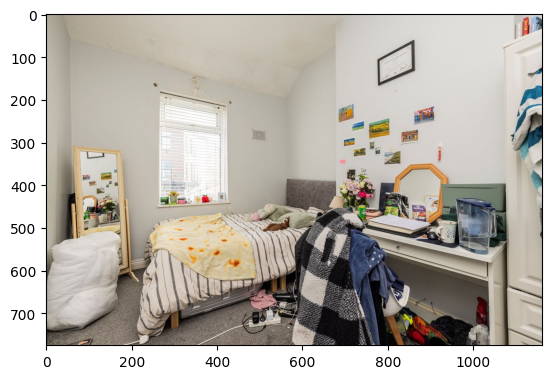

In [14]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("images/input_image_ex4.jpg")
original_image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(original_image)

Cany model...
stable diffusion model ...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Generation en cours ....


  0%|          | 0/20 [00:00<?, ?it/s]

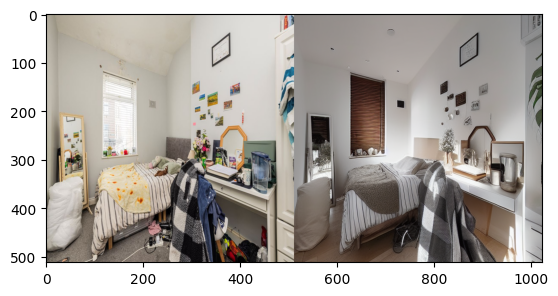

In [22]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler


image_path = "images/input_image_ex4.jpg"
orig_image = Image.open(image_path).convert("RGB")

resized_img = orig_image.resize((512, 512))

img_np = np.array(resized_img)


low_threshold = 100
high_threshold = 200


image = cv2.Canny(img_np, low_threshold, high_threshold)

image = image[:, :, None]
image = np.concatenate([image, image, image], axis=2)


image = Image.fromarray(image)

print("Cany model...")

controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=torch.float32
)

print("stable diffusion model ...")

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float32,
).to("cpu")

pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)



prompt = (
    "Photorealistic modern minimalist bedroom, neatly made bed with "
    "white linen and beige pillows, elegant wooden bedside table, "
    "warm wood accents, neutral beige and white colors, soft natural "
    "sunlight through the existing window, cozy ambient lighting, "
    "simple tasteful decor, clean surfaces, realistic materials, "
    "professional interior photography, preserve the original room "
    "layout, walls, windows, furniture positions and camera angle"
)

negative_prompt = (
    "clutter, messy bed, scattered clothes, trash, excessive decor, "
    "duplicated furniture, floating objects, deformed furniture, "
    "warped walls, distorted perspective, extra windows, missing doors, "
    "unnatural shadows, unrealistic textures, blurry, low resolution, "
    "noise, artifacts, oversaturated, cartoon, illustration, text, watermark"
)

print("Generation en cours ....")

redesigned_image = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=image,
    guidance_scale=7.5,
    num_inference_steps=20
).images[0]



w, h = resized_img.size
comparison = Image.new("RGB", (w * 2, h))
comparison.paste(resized_img, (0, 0))
comparison.paste(redesigned_image, (w, 0))

comparison.save("results/ex4_output_comparaison.png")
redesigned_image.save("results/ex4_output_after.png")
plt.imshow(comparison)